# SHAP-Guided SMOTE Benchmark: Stroke Prediction

**Research question.** Does using SHAP feature attributions *inside* the oversampler produce better synthetic
minority samples, and better minority-class classification, than conventional oversampling?

This notebook is one of four that run **the same experiment** on different datasets
(`01` Breast Cancer, `02` Credit Card Fraud, `03` Stroke, `04` NSL-KDD). All four are generated from one template
(`scripts/build_experiment_notebooks.py`) and import every algorithm from `src/`, so the only difference between
them is the dataset loaded in the first code cell. `05_cross_dataset_comparison.ipynb` compares the four.

| | Method | Type | How it creates minority samples |
|---|---|---|---|
| 0 | **No Sampling** | reference | none, trains on the imbalanced data |
| 1 | **Random Oversampling** | established | duplicates random minority rows |
| 2 | **SMOTE** | established (Chawla et al., 2002) | interpolates between a minority row and one of its k nearest minority neighbours (Euclidean) |
| 3 | **Borderline-SMOTE** | established (Han et al., 2005) | SMOTE, but only from minority rows near the class boundary (DANGER rows) |
| 4 | **SHAP-Filtered SMOTE** | **proposed** | SMOTE whose neighbours are searched only on the features that hold 90% of the SHAP importance |
| 5 | **SHAP-Weighted SMOTE** | **proposed** | SMOTE whose neighbour distance weights every feature by its SHAP importance: $d_W=\sqrt{\sum_j w_j (a_j-b_j)^2}$ |

**Stages:** 1 ingestion → 2 EDA → 3 leak-free preprocessing → 4 oversampling and synthetic-sample inspection →
5 repeated cross-validation → 6 hold-out test evaluation → 7 SHAP explainability comparison → 8 saved outputs,
summary and interpretation.

In [1]:
import sys, warnings
from pathlib import Path

# Locate the repository root (the folder that contains src/), wherever the notebook is run from
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "experiment").is_dir())
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.experiment import config as C
from src.experiment import data as D, preprocessing as P, runner as R, inspection as I
from src.experiment import plots as PL, outputs as O, summary as S

%matplotlib inline
PL.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATASET = "stroke"   # <- the only line that differs between the four dataset notebooks
DIRS = O.results_dirs(DATASET)
PLOTS = DIRS["plots"]
display(C.settings_table())

,Value
Setting,
Random seed,42
Hold-out test size,"25% (stratified, untouched)"
Cross-validation,2 x 5-fold stratified on the development set
Oversampling target,1:1 minority:majority (sampling_strategy='auto')
k neighbours (all SMOTE variants),5
Borderline-SMOTE m neighbours,10
SHAP-Filtered cumulative threshold,0.9000
SHAP preliminary model,"Random Forest, 50 trees, depth 5 (training fol..."
SHAP rows explained,"all rows up to 20,000; above that all minority..."


## Stage 1: Data ingestion
The loader drops identifier and non-feature columns, exact duplicate rows and constant columns, and records any
one-off subsampling that fixes the imbalance ratio. None of these steps learns anything from the data. The
DataFrame index is the **original row number in the source file**, so every synthetic sample can later be traced
back to two real records.

In [2]:
df, spec = D.load_dataset(DATASET)
display(pd.Series({"Source": spec.source, "URL": spec.url, "License": spec.license, "File": spec.file,
                   "Target": spec.target_definition}, name=spec.title).to_frame())
display(Markdown("**Dataset-level steps applied by the loader:**\n" + "\n".join(f"- {n}" for n in spec.notes)))
print(f"Shape after loading: {df.shape[0]:,} rows x {df.shape[1] - 1} features + target")
display(df.head())

,Stroke Prediction
Source,Kaggle fedesoriano/stroke-prediction-dataset (...
URL,https://www.kaggle.com/datasets/fedesoriano/st...
License,Data files (c) original authors (Kaggle listin...
File,data/kaggle_stroke/healthcare-dataset-stroke-d...
Target,stroke == 1


**Dataset-level steps applied by the loader:**
- `bmi` is stored as text 'N/A' for some patients; read as missing and median-imputed inside each training fold.

Shape after loading: 5,110 rows x 10 features + target


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,target
row_id,,,,,,,,,,,
0,Male,67.0000,0,1,Yes,Private,Urban,228.6900,36.6000,formerly smoked,1
1,Female,61.0000,0,0,Yes,Self-employed,Rural,202.2100,NaN,never smoked,1
2,Male,80.0000,0,1,Yes,Private,Rural,105.9200,32.5000,never smoked,1
3,Female,49.0000,0,0,Yes,Private,Urban,171.2300,34.4000,smokes,1
4,Female,79.0000,1,0,Yes,Self-employed,Rural,174.1200,24.0000,never smoked,1


In [3]:
quality = D.quality_report(df, spec)
print(f"Numerical features ({len(spec.numeric_features)}): {', '.join(spec.numeric_features[:12])}"
      + (" ..." if len(spec.numeric_features) > 12 else ""))
print(f"Categorical features ({len(spec.categorical_features)}): {', '.join(spec.categorical_features) or 'none'}")
display(D.quality_summary(df, spec))
display(quality.sort_values("Missing", ascending=False).head(12))

Numerical features (5): age, hypertension, heart_disease, avg_glucose_level, bmi
Categorical features (5): gender, ever_married, work_type, Residence_type, smoking_status


,Count,Handling
Check,,
Missing cells,201,Median / most-frequent imputation fitted on ea...
Infinite cells,0,Would be set to missing
Duplicate rows remaining,0,Exact duplicates already dropped at load time
Rows with |z| > 5 on any numeric feature,4,Flagged only: in imbalanced problems extreme r...
Categorical features,5,One-hot encoded inside each training fold


,Type,dtype,Missing,Unique,Min,Max,Binary 0/1
Feature,,,,,,,
bmi,numeric,float64,201,418,10.3000,97.6000,False
age,numeric,float64,0,104,0.0800,82.0000,False
hypertension,numeric,int64,0,2,0.0000,1.0000,True
heart_disease,numeric,int64,0,2,0.0000,1.0000,True
avg_glucose_level,numeric,float64,0,3979,55.1200,271.7400,False
gender,categorical,str,0,3,NaN,NaN,False
ever_married,categorical,str,0,2,NaN,NaN,False
work_type,categorical,str,0,5,NaN,NaN,False
Residence_type,categorical,str,0,2,NaN,NaN,False


## Stage 2: Exploratory data analysis
EDA is descriptive only. The Kolmogorov-Smirnov ranking below only chooses which features to plot; it is never
used by any model or oversampler.

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Stroke Prediction,Clinical risk prediction,5110,5,5,4861,249,4.87%,19.5 : 1,1 : 19.5


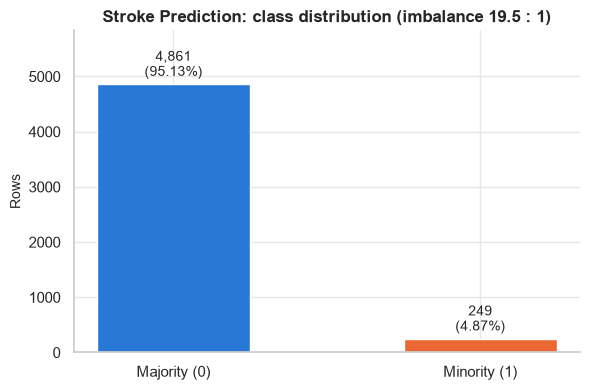

In [4]:
display(D.overview(df, spec))
PL.class_distribution(df, spec.title, PLOTS); plt.show()

,KS D (majority vs minority)
age,0.5409
avg_glucose_level,0.2402
hypertension,0.1762
bmi,0.1698
heart_disease,0.1416


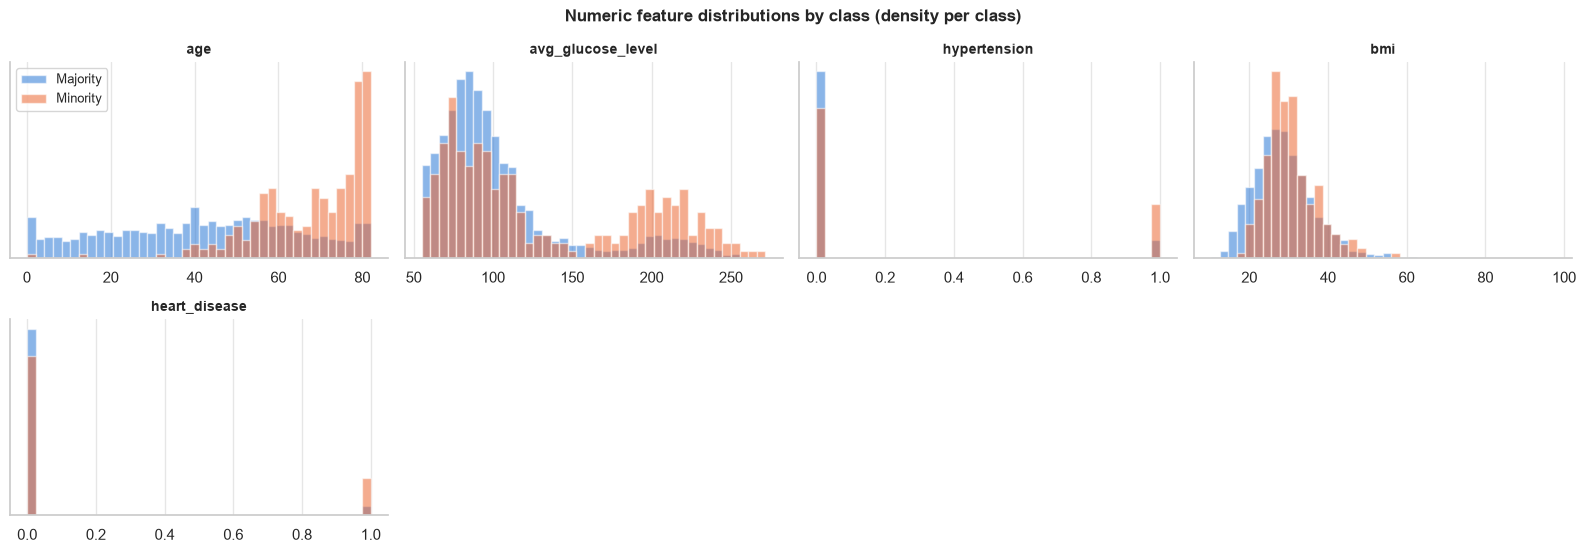

In [5]:
ks = D.ks_ranking(df, spec)
display(ks.head(10).to_frame("KS D (majority vs minority)"))
TOP_KS = list(ks.index[:8])
PL.feature_distributions(df, TOP_KS, PLOTS); plt.show()

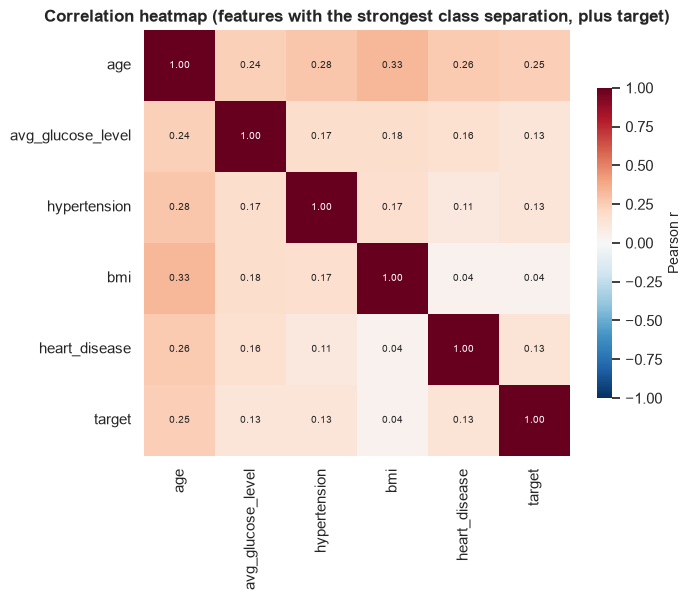

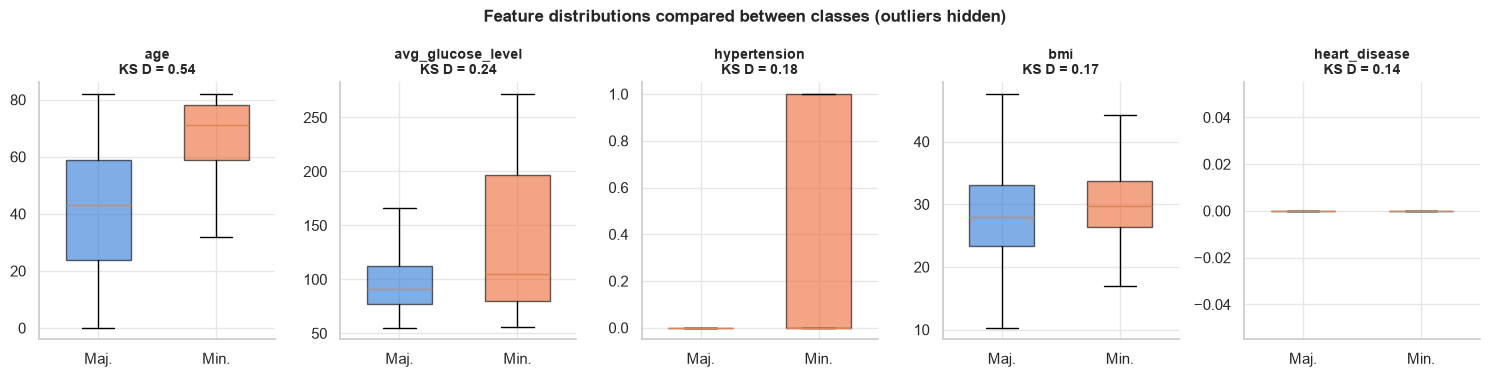

In [6]:
PL.correlation_heatmap(df, list(ks.index[:12]), PLOTS); plt.show()
PL.class_comparison(df, TOP_KS[:6], ks, PLOTS); plt.show()

## Stage 3: Leak-free preprocessing
```
full data --stratified 25%--> TEST (never resampled; used once, in Stage 6)
   └── DEVELOPMENT (75%) ── repeated stratified k-fold (Stage 5); in each fold, on the training part only:
                            impute + encode + scale  →  SHAP (inside the SHAP samplers)  →  oversample  →  fit model
```
Missing values: median (numeric) / most frequent (categorical) imputation. Categorical features are one-hot
encoded and numeric features are standardised. Every one of these steps is fitted on training rows only. The
table below shows the final fit on the whole development set: the scaler makes the development data exactly
mean 0, while the test set is only *close* to 0, because the test set was never used to fit anything.

In [7]:
dev_df, test_df = P.split_dev_test(df)
split = pd.DataFrame({"Rows": [len(dev_df), len(test_df)],
                      "Majority (0)": [int((dev_df.target == 0).sum()), int((test_df.target == 0).sum())],
                      "Minority (1)": [int(dev_df.target.sum()), int(test_df.target.sum())]},
                     index=["Development (75%)", "Hold-out test (25%)"])
split["Minority %"] = (split["Minority (1)"] / split["Rows"]).map("{:.2%}".format)
display(split)
assert not set(dev_df.index) & set(test_df.index), "development and test rows overlap"

pre = P.Preprocessor(spec).fit(dev_df)
print(f"Model space after encoding: {len(pre.feature_names_)} columns "
      f"({pre.n_numeric_} scaled numeric + {len(pre.feature_names_) - pre.n_numeric_} one-hot)")
display(pre.summary(dev_df, test_df).head(15))

,Rows,Majority (0),Minority (1),Minority %
Development (75%),3832,3645,187,4.88%
Hold-out test (25%),1278,1216,62,4.85%


Model space after encoding: 21 columns (5 scaled numeric + 16 one-hot)


,Kind,Missing (train),Imputation value (train median),Scaler mean (train),Scaler std (train),Train mean after,Test mean after
Feature,,,,,,,
age,numeric,0,45.0000,43.3122,22.5660,0.0000,-0.0152
hypertension,numeric,0,0.0000,0.0963,0.2950,-0.0000,0.0157
heart_disease,numeric,0,0.0000,0.0532,0.2245,0.0000,0.0138
avg_glucose_level,numeric,0,91.8500,105.8755,44.8206,-0.0000,0.0243
bmi,numeric,158,28.0000,28.8512,7.7155,-0.0000,0.0036
gender,categorical -> 3 one-hot columns,0,NaN,NaN,NaN,NaN,NaN
ever_married,categorical -> 2 one-hot columns,0,NaN,NaN,NaN,NaN,NaN
work_type,categorical -> 5 one-hot columns,0,NaN,NaN,NaN,NaN,NaN
Residence_type,categorical -> 2 one-hot columns,0,NaN,NaN,NaN,NaN,NaN


## Stage 4: Oversampling and synthetic-sample inspection
The cell below fits **every sampler on the preprocessed development set** (the same chain is re-run inside every
CV fold in Stage 5) and fits the three downstream models on each resampled set. Test-set scores are only reported
in Stage 6.

All SMOTE-family methods share one generation engine (`src/oversampling/provenance.py`):
$x_{new} = x_a + \lambda (x_{nn} - x_a)$ with $\lambda \sim U(0,1)$, interpolated in the full, unweighted feature space.
They differ only in **which rows can be anchors** $x_a$ and **in which space the neighbour $x_{nn}$ is searched**.
They also share one random seed. For SMOTE, SHAP-Filtered SMOTE and SHAP-Weighted SMOTE (which all draw anchors
from every minority row), synthetic row *i* therefore has the same anchor, the same neighbour rank and the same
$\lambda$, so any difference between these three comes from neighbour selection alone. Borderline-SMOTE draws
from a smaller anchor pool, so its rows pair up differently. The engine records the parents, neighbour rank,
distance and $\lambda$ of every synthetic row.

No Sampling            sampled in    0.0 s, 3 models fitted and scored on the test set


Random Oversampling    sampled in    1.4 s, 3 models fitted and scored on the test set


SMOTE                  sampled in    0.2 s, 3 models fitted and scored on the test set


Borderline-SMOTE       sampled in    0.2 s, 3 models fitted and scored on the test set


SHAP-Filtered SMOTE    sampled in    2.4 s, 3 models fitted and scored on the test set


SHAP-Weighted SMOTE    sampled in    2.4 s, 3 models fitted and scored on the test set


,Anchor pool,Neighbour search space,Features in search,Search features (first 8),Synthetic rows
Method,,,,,
No Sampling,-,-,0,-,0
Random Oversampling,all minority rows,none (exact copies),0,-,3458
SMOTE,all minority rows,all features (Euclidean),21,"age, hypertension, heart_disease, avg_glucose_...",3458
Borderline-SMOTE,DANGER rows only (108 of 187),all features (Euclidean),21,"age, hypertension, heart_disease, avg_glucose_...",3458
SHAP-Filtered SMOTE,all minority rows,10 SHAP-selected features (Euclidean),10,"age, hypertension, heart_disease, avg_glucose_...",3458
SHAP-Weighted SMOTE,all minority rows,"all features, column j scaled by sqrt(w_j)",21,"age, hypertension, heart_disease, avg_glucose_...",3458


,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds
method,,,,,,
No Sampling,3645,187,0,3645,187,0.0061
Random Oversampling,3645,187,3458,3645,3645,1.3882
SMOTE,3645,187,3458,3645,3645,0.1861
Borderline-SMOTE,3645,187,3458,3645,3645,0.1917
SHAP-Filtered SMOTE,3645,187,3458,3645,3645,2.4048
SHAP-Weighted SMOTE,3645,187,3458,3645,3645,2.4121


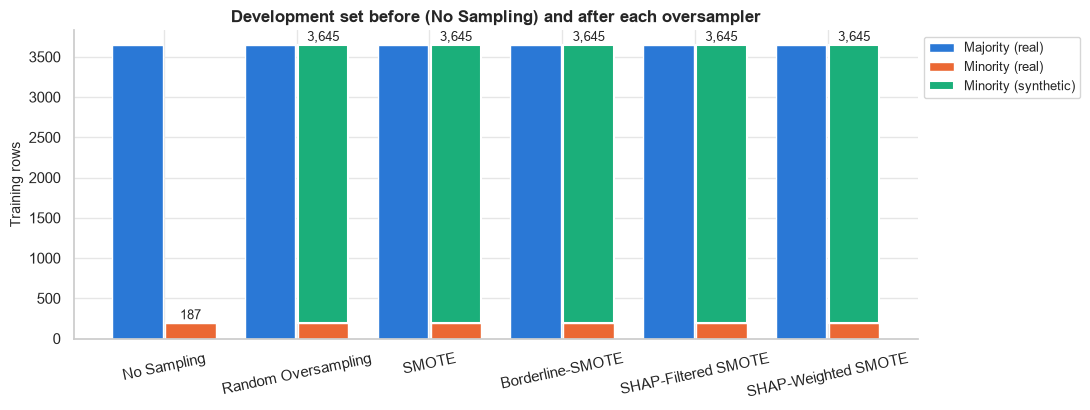

In [8]:
final = R.run_final(dev_df, test_df, spec)
display(I.search_space_description(final))
display(final.sampling)
PL.balanced_class_counts(final, PLOTS); plt.show()

### 4A. Neighbour identification
For each method: the k = 5 nearest minority neighbours of the first two minority seeds, the distance in the
method's search space, the plain Euclidean distance, the rank the same neighbour would have under plain SMOTE,
and the features that make up most of the search distance. For Borderline-SMOTE each seed is also labelled
SAFE / DANGER / NOISE from its 10 nearest neighbours in the whole training set; only DANGER rows can be anchors.

In [9]:
seed_ids = final.dev_row_ids[final.samplers["SMOTE"].minority_positions_[:2]]
for m in I.INTERPOLATING:
    t = I.neighbour_table(final, m, max_seeds=2)
    display(Markdown(f"**{m}**"))
    display(t.drop(columns="method"))
bl = final.samplers["Borderline-SMOTE"]
display(pd.Series({"SAFE": int(bl.safe_mask_.sum()), "DANGER (anchors)": int(bl.danger_mask_.sum()),
                   "NOISE": int(bl.noise_mask_.sum())}, name="Borderline-SMOTE seed status").to_frame())
display(I.neighbour_overlap_with_smote(final))

**SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,105,1,117,0.8539,0.8539,1,"age (69%), bmi (25%), avg_glucose_level (6%)"
1,105,2,84,1.4357,1.4357,2,"smoking_status=smokes (49%), smoking_status=Un..."
2,105,3,41,1.4480,1.4480,3,"smoking_status=smokes (48%), smoking_status=ne..."
3,105,4,85,1.4693,1.4693,4,"Residence_type=Urban (46%), Residence_type=Rur..."
4,105,5,172,1.4713,1.4713,5,"gender=Female (46%), gender=Male (46%), avg_gl..."
5,81,1,104,1.4847,1.4847,1,"work_type=Self-employed (45%), work_type=Govt_..."
6,81,2,112,1.4861,1.4861,2,"smoking_status=formerly smoked (45%), smoking_..."
7,81,3,178,1.5579,1.5579,3,"work_type=Self-employed (41%), work_type=Govt_..."
8,81,4,129,1.7073,1.7073,4,"work_type=Self-employed (34%), work_type=Govt_..."
9,81,5,127,1.7440,1.7440,5,"work_type=Private (33%), work_type=Self-employ..."


**Borderline-SMOTE**

,seed_row_id,seed_status,majority_in_10_nn,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,105,NOISE,10,1,117,0.8539,0.8539,1,"age (69%), bmi (25%), avg_glucose_level (6%)"
1,105,NOISE,10,2,84,1.4357,1.4357,2,"smoking_status=smokes (49%), smoking_status=Un..."
2,105,NOISE,10,3,41,1.4480,1.4480,3,"smoking_status=smokes (48%), smoking_status=ne..."
3,105,NOISE,10,4,85,1.4693,1.4693,4,"Residence_type=Urban (46%), Residence_type=Rur..."
4,105,NOISE,10,5,172,1.4713,1.4713,5,"gender=Female (46%), gender=Male (46%), avg_gl..."
5,81,NOISE,10,1,104,1.4847,1.4847,1,"work_type=Self-employed (45%), work_type=Govt_..."
6,81,NOISE,10,2,112,1.4861,1.4861,2,"smoking_status=formerly smoked (45%), smoking_..."
7,81,NOISE,10,3,178,1.5579,1.5579,3,"work_type=Self-employed (41%), work_type=Govt_..."
8,81,NOISE,10,4,129,1.7073,1.7073,4,"work_type=Self-employed (34%), work_type=Govt_..."
9,81,NOISE,10,5,127,1.7440,1.7440,5,"work_type=Private (33%), work_type=Self-employ..."


**SHAP-Filtered SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,105,1,41,0.3110,1.4480,3,"avg_glucose_level (63%), age (32%), bmi (4%)"
1,105,2,85,0.3986,1.4693,4,"avg_glucose_level (67%), age (20%), bmi (13%)"
2,105,3,172,0.4060,1.4713,5,"avg_glucose_level (69%), bmi (26%), age (5%)"
3,105,4,204,0.4563,2.0514,15,"bmi (78%), age (15%), avg_glucose_level (7%)"
4,105,5,74,0.4641,2.4931,42,"avg_glucose_level (47%), age (33%), bmi (20%)"
5,81,1,197,1.0251,2.4599,45,"work_type=Self-employed (95%), avg_glucose_lev..."
6,81,2,64,1.0791,2.0407,12,"work_type=Self-employed (86%), age (14%), avg_..."
7,81,3,104,1.0974,1.4847,1,"work_type=Self-employed (83%), age (13%), avg_..."
8,81,4,153,1.1358,2.0712,16,"smoking_status=Unknown (78%), avg_glucose_leve..."
9,81,5,209,1.1459,2.0768,18,"work_type=Self-employed (76%), bmi (22%), age ..."


**SHAP-Weighted SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,105,1,84,0.1763,1.4357,2,"smoking_status=Unknown (50%), avg_glucose_leve..."
1,105,2,236,0.1926,1.4966,7,"smoking_status=Unknown (42%), bmi (32%), smoki..."
2,105,3,172,0.1929,1.4713,5,"avg_glucose_level (39%), gender=Female (23%), ..."
3,105,4,41,0.2079,1.4480,3,"smoking_status=never smoked (33%), age (30%), ..."
4,105,5,85,0.2173,1.4693,4,"avg_glucose_level (29%), age (28%), Residence_..."
5,81,1,209,0.2728,2.0768,18,"work_type=Self-employed (36%), bmi (20%), Resi..."
6,81,2,153,0.2818,2.0712,16,"avg_glucose_level (45%), smoking_status=Unknow..."
7,81,3,197,0.2970,2.4599,45,"work_type=Self-employed (30%), work_type=Priva..."
8,81,4,170,0.2975,2.4623,46,"smoking_status=formerly smoked (30%), smoking_..."
9,81,5,99,0.3012,2.0471,13,"work_type=Self-employed (29%), avg_glucose_lev..."


,Borderline-SMOTE seed status
SAFE,2
DANGER (anchors),108
NOISE,77


,mean_jaccard_with_SMOTE_neighbours,seeds_with_identical_neighbours
method,,
SMOTE,1.0000,1.0000
Borderline-SMOTE,1.0000,1.0000
SHAP-Filtered SMOTE,0.3821,0.0481
SHAP-Weighted SMOTE,0.3614,0.0321


### 4B. Synthetic sample generation
Below are the first synthetic records of each method, with their two parents (original row ids), $\lambda$ and
neighbour rank, followed by a feature-by-feature walk through synthetic row #0 of every interpolating method.
Because of the shared seed, row #0 of SMOTE, SHAP-Filtered and SHAP-Weighted SMOTE has the same anchor and the
same $\lambda$, so you can see how the choice of neighbour changes the result (Borderline-SMOTE's anchor comes
from its DANGER pool). A Random Oversampling record is an exact copy of parent 1.

In [10]:
for m in C.OVERSAMPLERS:
    rec = I.generation_records(final, m)
    display(Markdown(f"**{m}**: {len(rec):,} synthetic rows"))
    display(rec.head(4).iloc[:, :14])

**Random Oversampling**: 3,458 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,age,hypertension,heart_disease,avg_glucose_level,bmi,gender
0,1-0,Random Oversampling,113,NaN,NaN,NaN,NaN,1,45.0000,0.0000,0.0000,224.1000,56.6000,Female
1,1-1,Random Oversampling,127,NaN,NaN,NaN,NaN,1,80.0000,0.0000,0.0000,73.5400,24.0000,Female
2,1-2,Random Oversampling,55,NaN,NaN,NaN,NaN,1,63.0000,0.0000,1.0000,196.7100,36.5000,Male
3,1-3,Random Oversampling,144,NaN,NaN,NaN,NaN,1,72.0000,1.0000,0.0000,221.7900,30.0000,Female


**SMOTE**: 3,458 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,age,hypertension,heart_disease,avg_glucose_level,bmi,gender
0,2-0,SMOTE,67,200.0000,4,0.4389,1.7200,1,75.1222,0.0000,0.0000,131.9701,23.6794,Male
1,2-1,SMOTE,201,115.0000,5,0.6974,3.0048,1,73.7237,1.0000,1.0000,204.3354,31.0816,Male
2,2-2,SMOTE,135,66.0000,1,0.9756,2.0421,1,70.0244,0.0000,0.0000,222.5975,47.2855,Female
3,2-3,SMOTE,170,246.0000,4,0.7861,1.6775,1,72.6467,0.0000,0.0000,85.8984,29.0219,Female


**Borderline-SMOTE**: 3,458 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,age,hypertension,heart_disease,avg_glucose_level,bmi,gender
0,3-0,Borderline-SMOTE,67,200.0000,4,0.4389,1.7200,1,75.1222,0.0000,0.0000,131.9701,23.6794,Male
1,3-1,Borderline-SMOTE,121,164.0000,5,0.6974,2.2748,1,64.8553,1.0000,0.0000,81.0860,33.0197,Female
2,3-2,Borderline-SMOTE,19,225.0000,1,0.9756,2.4802,1,57.0000,0.0000,1.0000,216.5922,30.9269,Female
3,3-3,Borderline-SMOTE,23,151.0000,4,0.7861,2.1239,1,70.9951,0.0000,1.0000,220.5076,32.0284,Male


**SHAP-Filtered SMOTE**: 3,458 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,age,hypertension,heart_disease,avg_glucose_level,bmi,gender
0,4-0,SHAP-Filtered SMOTE,67,64.0000,4,0.4389,0.9990,1,75.5611,0.0000,0.0000,104.5797,23.6794,Male
1,4-1,SHAP-Filtered SMOTE,201,193.0000,5,0.6974,2.4323,1,71.6316,1.0000,1.0000,242.5511,31.2211,Male
2,4-2,SHAP-Filtered SMOTE,135,122.0000,1,0.9756,0.9945,1,79.7806,0.0000,0.0000,259.7200,31.8706,Male
3,4-3,SHAP-Filtered SMOTE,170,146.0000,4,0.7861,0.9727,1,64.7861,0.0000,0.0000,77.7469,28.0000,Male


**SHAP-Weighted SMOTE**: 3,458 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,age,hypertension,heart_disease,avg_glucose_level,bmi,gender
0,5-0,SHAP-Weighted SMOTE,67,127.0000,4,0.4389,0.3212,1,77.7555,0.0000,0.0000,90.8955,21.9239,Male
1,5-1,SHAP-Weighted SMOTE,201,217.0000,5,0.6974,0.8408,1,62.5658,1.0000,1.0000,199.7746,37.4276,Female
2,5-2,SHAP-Weighted SMOTE,135,102.0000,1,0.9756,0.4059,1,73.9269,0.0000,0.0000,232.3830,34.6999,Female
3,5-3,SHAP-Weighted SMOTE,170,181.0000,4,0.7861,0.3073,1,60.0697,0.0000,0.0000,111.2411,31.1443,Male


In [11]:
for m in I.INTERPOLATING:
    if final.samplers[m].n_synthetic_ == 0:
        continue
    ex = I.example_walkthrough(final, m, 0, max_features=8)
    display(Markdown(f"**{ex.attrs['header']}**"))
    display(ex)

**SMOTE: synthetic #0 = parent_1 (row 67) + 0.4389 x (parent_2 (row 200) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
age,76.0000,74.0000,-2.0000,-0.8778,75.1222
hypertension,0.0000,0.0000,0.0000,0.0000,0.0000
heart_disease,0.0000,0.0000,0.0000,0.0000,0.0000
avg_glucose_level,104.4700,167.1300,62.6600,27.5001,131.9701
bmi,20.3000,28.0000,7.7000,3.3794,23.6794
gender,Male,Male,NaN,NaN,Male
ever_married,Yes,Yes,NaN,NaN,Yes
work_type,Private,Private,NaN,NaN,Private


**Borderline-SMOTE: synthetic #0 = parent_1 (row 67) + 0.4389 x (parent_2 (row 200) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
age,76.0000,74.0000,-2.0000,-0.8778,75.1222
hypertension,0.0000,0.0000,0.0000,0.0000,0.0000
heart_disease,0.0000,0.0000,0.0000,0.0000,0.0000
avg_glucose_level,104.4700,167.1300,62.6600,27.5001,131.9701
bmi,20.3000,28.0000,7.7000,3.3794,23.6794
gender,Male,Male,NaN,NaN,Male
ever_married,Yes,Yes,NaN,NaN,Yes
work_type,Private,Private,NaN,NaN,Private


**SHAP-Filtered SMOTE: synthetic #0 = parent_1 (row 67) + 0.4389 x (parent_2 (row 64) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
age,76.0000,75.0000,-1.0000,-0.4389,75.5611,0.4191
avg_glucose_level,104.4700,104.7200,0.2500,0.1097,104.5797,0.1278
ever_married,Yes,Yes,NaN,NaN,Yes,0.0961
hypertension,0.0000,0.0000,0.0000,0.0000,0.0000,0.0741
heart_disease,0.0000,0.0000,0.0000,0.0000,0.0000,0.0727
smoking_status,Unknown,Unknown,NaN,NaN,Unknown,0.0637
work_type,Private,Private,NaN,NaN,Private,0.0579
bmi,20.3000,28.0000,7.7000,3.3794,23.6794,0.0521


**SHAP-Weighted SMOTE: synthetic #0 = parent_1 (row 67) + 0.4389 x (parent_2 (row 127) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
age,76.0000,80.0000,4.0000,1.7555,77.7555,0.4191
avg_glucose_level,104.4700,73.5400,-30.9300,-13.5745,90.8955,0.1278
ever_married,Yes,Yes,NaN,NaN,Yes,0.0961
hypertension,0.0000,0.0000,0.0000,0.0000,0.0000,0.0741
heart_disease,0.0000,0.0000,0.0000,0.0000,0.0000,0.0727
smoking_status,Unknown,Unknown,NaN,NaN,Unknown,0.0637
work_type,Private,Private,NaN,NaN,Private,0.0579
bmi,20.3000,24.0000,3.7000,1.6239,21.9239,0.0521


### 4C. SHAP guidance
Both proposed methods first fit a preliminary Random Forest (50 trees, depth 5) **on the training data only**,
explain it with `shap.TreeExplainer`, and turn the mean absolute SHAP value of each feature (MASV) into a weight
$w_j = \text{MASV}_j / \sum_k \text{MASV}_k$.
* **SHAP-Filtered SMOTE** searches neighbours only on the top features whose cumulative weight reaches 90%.
* **SHAP-Weighted SMOTE** multiplies every column by $\sqrt{w_j}$ before the Euclidean search, so the distance becomes
  $d_W(a,b)=\sqrt{\sum_j w_j (a_j-b_j)^2}$: high-SHAP features decide who counts as a neighbour.

The rationale tables show, for the first synthetic rows, the neighbour's rank in SHAP space and under plain SMOTE,
which features made up the SHAP distance, and how similar the two parents' SHAP explanations are (cosine).

,rank,MASV,weight_w,cumulative_weight,sqrt_w_stretch_vs_uniform,kept_by_SHAP_Filtered
age,1,0.0255,0.4191,0.4191,2.9667,True
avg_glucose_level,2,0.0078,0.1278,0.5469,1.6383,True
hypertension,3,0.0045,0.0741,0.6210,1.2472,True
heart_disease,4,0.0044,0.0727,0.6936,1.2352,True
bmi,5,0.0032,0.0521,0.7458,1.0463,True
ever_married=Yes,6,0.0030,0.0490,0.7948,1.0146,True
ever_married=No,7,0.0029,0.0471,0.8419,0.9948,True
work_type=Self-employed,8,0.0016,0.0265,0.8684,0.7453,True
smoking_status=formerly smoked,9,0.0016,0.0261,0.8945,0.7407,True
smoking_status=Unknown,10,0.0010,0.0156,0.9101,0.5722,True


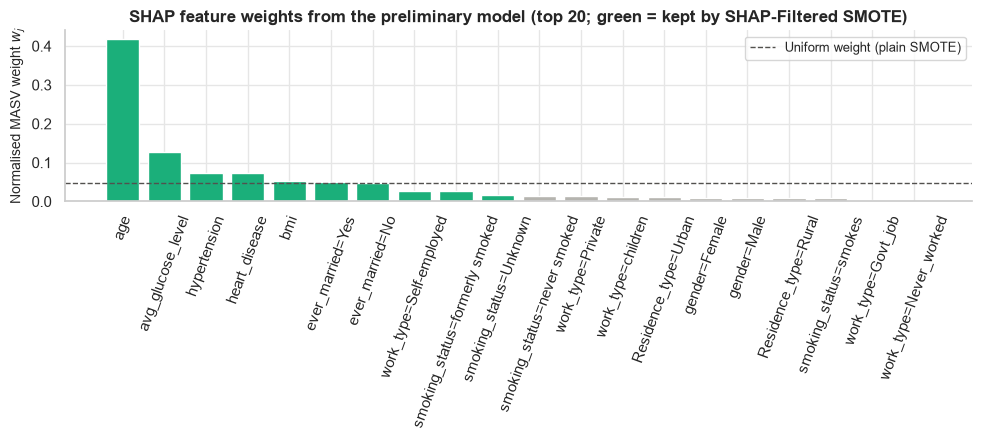

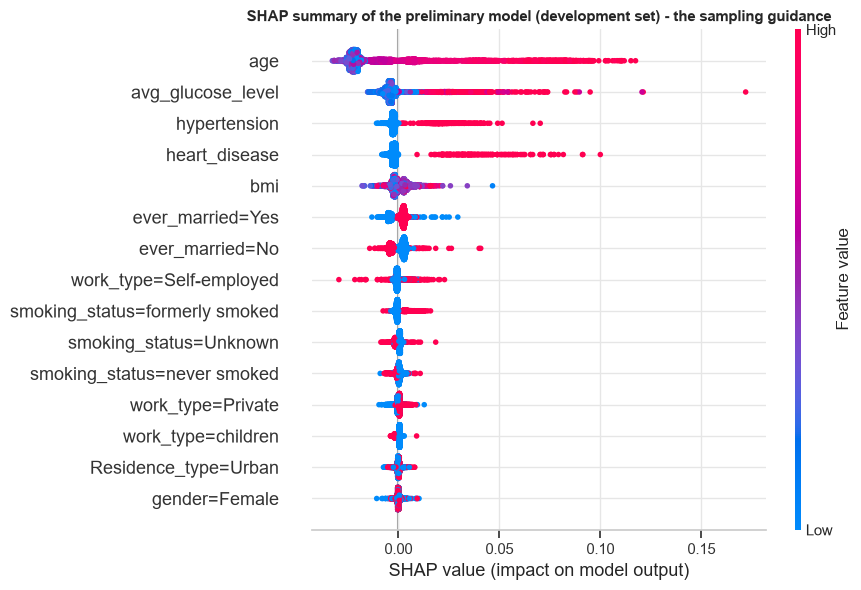

In [12]:
weights = I.shap_weight_table(final)
display(weights.head(15))
PL.masv_weights(weights, PLOTS); plt.show()
PL.shap_summary(final, PLOTS); plt.show()

In [13]:
for m in C.PROPOSED_METHODS:
    r = I.shap_rationale(final, m, n=8)
    display(Markdown(f"**{m}: neighbour-selection rationale (first 8 synthetic rows)**"))
    display(r)
    moved = (~r["would_plain_SMOTE_consider_it"]).mean()
    print(f"{moved:.0%} of these parent pairs would NOT be neighbours under plain SMOTE")
display(Markdown("**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**"))
display(I.parent_shap_detail(final, "SHAP-Weighted SMOTE", 0))

**SHAP-Filtered SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [age],SHAP p1/p2 [avg_glucose_level],SHAP p1/p2 [hypertension],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,67,64,0.4389,4,1,0.9930,"bmi (100%), age (0%), avg_glucose_level (0%)",+0.092 / +0.081,+0.005 / +0.004,-0.002 / -0.001,True
1,201,193,0.6974,5,4,0.7260,"avg_glucose_level (78%), smoking_status=former...",+0.076 / +0.064,+0.036 / +0.172,+0.006 / +0.032,True
2,135,122,0.9756,1,16,0.9500,"bmi (83%), age (16%), avg_glucose_level (1%)",+0.067 / +0.095,+0.121 / +0.095,-0.003 / -0.005,False
3,170,146,0.7861,4,7,0.9710,"avg_glucose_level (100%), age (0%), smoking_st...",+0.013 / +0.020,-0.002 / -0.003,-0.001 / -0.003,False
4,148,238,0.4504,1,5,0.7300,"bmi (54%), avg_glucose_level (34%), age (11%)",+0.003 / -0.011,+0.002 / -0.007,+0.028 / +0.018,True
5,10,69,0.9268,2,1,0.9680,"work_type=Self-employed (96%), avg_glucose_lev...",+0.083 / +0.085,-0.006 / +0.008,+0.026 / +0.037,True
6,134,233,0.8228,4,6,0.9080,"smoking_status=formerly smoked (83%), age (13%...",+0.031 / +0.068,+0.019 / +0.017,+0.024 / +0.020,False
7,216,169,0.2272,3,3,0.9900,"bmi (49%), avg_glucose_level (48%), age (3%)",+0.070 / +0.090,-0.003 / -0.007,-0.003 / -0.003,True


38% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [age],SHAP p1/p2 [avg_glucose_level],SHAP p1/p2 [hypertension],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,67,127,0.4389,4,3,0.9940,"avg_glucose_level (59%), age (13%), bmi (12%)",+0.092 / +0.091,+0.005 / -0.003,-0.002 / -0.003,True
1,201,217,0.6974,5,3,0.6240,"age (73%), avg_glucose_level (11%), bmi (9%)",+0.076 / -0.006,+0.036 / +0.043,+0.006 / +0.022,True
2,135,102,0.9756,1,8,0.8440,"avg_glucose_level (39%), smoking_status=former...",+0.067 / +0.085,+0.121 / +0.050,-0.003 / -0.001,False
3,170,181,0.7861,4,18,0.9210,"work_type=Self-employed (28%), age (22%), bmi ...",+0.013 / +0.007,-0.002 / -0.003,-0.001 / -0.001,False
4,148,121,0.4504,1,11,0.8510,"smoking_status=Unknown (18%), smoking_status=n...",+0.003 / -0.012,+0.002 / +0.005,+0.028 / +0.027,False
5,10,69,0.9268,2,1,0.9680,"work_type=Self-employed (58%), work_type=Priva...",+0.083 / +0.085,-0.006 / +0.008,+0.026 / +0.037,True
6,134,175,0.8228,4,4,0.9460,"bmi (62%), avg_glucose_level (18%), age (9%)",+0.031 / +0.039,+0.019 / +0.015,+0.024 / +0.020,True
7,216,48,0.2272,3,1,0.9910,"bmi (60%), avg_glucose_level (28%), age (12%)",+0.070 / +0.092,-0.003 / -0.005,-0.003 / -0.003,True


38% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**

,SHAP weight w_j,in search space,share of search distance,SHAP parent 1,SHAP parent 2,value parent 1 (scaled),value parent 2 (scaled),synthetic (scaled)
feature,,,,,,,,
age,0.4191,True,0.1277,0.0919,0.0914,1.4485,1.6258,1.5263
avg_glucose_level,0.1278,True,0.5901,0.0048,-0.0033,-0.0314,-0.7214,-0.3342
hypertension,0.0741,True,0.0000,-0.0020,-0.0033,-0.3264,-0.3264,-0.3264
heart_disease,0.0727,True,0.0000,-0.0029,-0.0022,-0.2371,-0.2371,-0.2371
bmi,0.0521,True,0.1162,0.0059,0.0082,-1.1083,-0.6288,-0.8978
ever_married=Yes,0.0490,True,0.0000,0.0033,0.0009,1.0000,1.0000,1.0000
ever_married=No,0.0471,True,0.0000,0.0016,0.0005,0.0000,0.0000,0.0000
work_type=Self-employed,0.0265,True,0.0000,0.0017,0.0025,0.0000,0.0000,0.0000
smoking_status=formerly smoked,0.0261,True,0.0000,-0.0015,-0.0017,0.0000,0.0000,0.0000


### 4D. Quality of the synthetic samples
* **majority_share_in_5nn**: share of majority rows among the 5 nearest real development rows of each synthetic
  row. Higher means more synthetic points sit in majority territory, a proxy for label noise. The real
  minority rows give the reference value.
* **Fidelity** of synthetic vs real minority rows: marginal Wasserstein distance, KS-test pass rate and
  correlation-matrix similarity (does the synthetic data keep the real feature relationships?).
* **parents_SHAP_cosine_mean**: how similar the explanations of the two parents are.
* **detectability_auc_all / _numeric**: cross-validated ROC-AUC of a Random Forest trained to tell real minority rows
  from synthetic ones (0.5 = indistinguishable, 1 = trivially separable), on all model columns and on the numeric
  columns only. **fractional_onehot_cols_per_row** counts one-hot columns that interpolation left between 0 and 1
  (datasets with categorical features only). A detectable synthetic class can teach a model an artefact that never
  appears in real test rows.

,synthetic_rows,majority_share_in_5nn,synthetic_with_majority_nn1_%,mean_wasserstein_distance,max_wasserstein_distance,ks_test_pass_ratio,covariance_frobenius_dist,correlation_matrix_similarity,parents_SHAP_cosine_mean,distinct_parent_pairs,fractional_onehot_cols_per_row,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,,,
Real minority (reference),0,0.8973,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Oversampling,3458,0.7193,0.0000,0.0074,0.0487,1.0000,0.1936,0.9958,NaN,NaN,NaN,NaN,NaN
SMOTE,3458,0.6787,15.9051,0.0403,0.0913,0.5714,0.3804,0.9846,0.7349,906.0000,2.3042,0.8082,0.6328
Borderline-SMOTE,3458,0.6313,12.8976,0.0649,0.1892,0.6190,0.9975,0.9064,0.8051,539.0000,2.1110,0.7720,0.6165
SHAP-Filtered SMOTE,3458,0.6912,12.9844,0.0579,0.1395,0.5238,0.4240,0.9883,0.8049,906.0000,3.7218,0.9251,0.5868
SHAP-Weighted SMOTE,3458,0.6903,9.3117,0.0588,0.1157,0.4762,0.4211,0.9839,0.8789,906.0000,3.9294,0.9621,0.5986


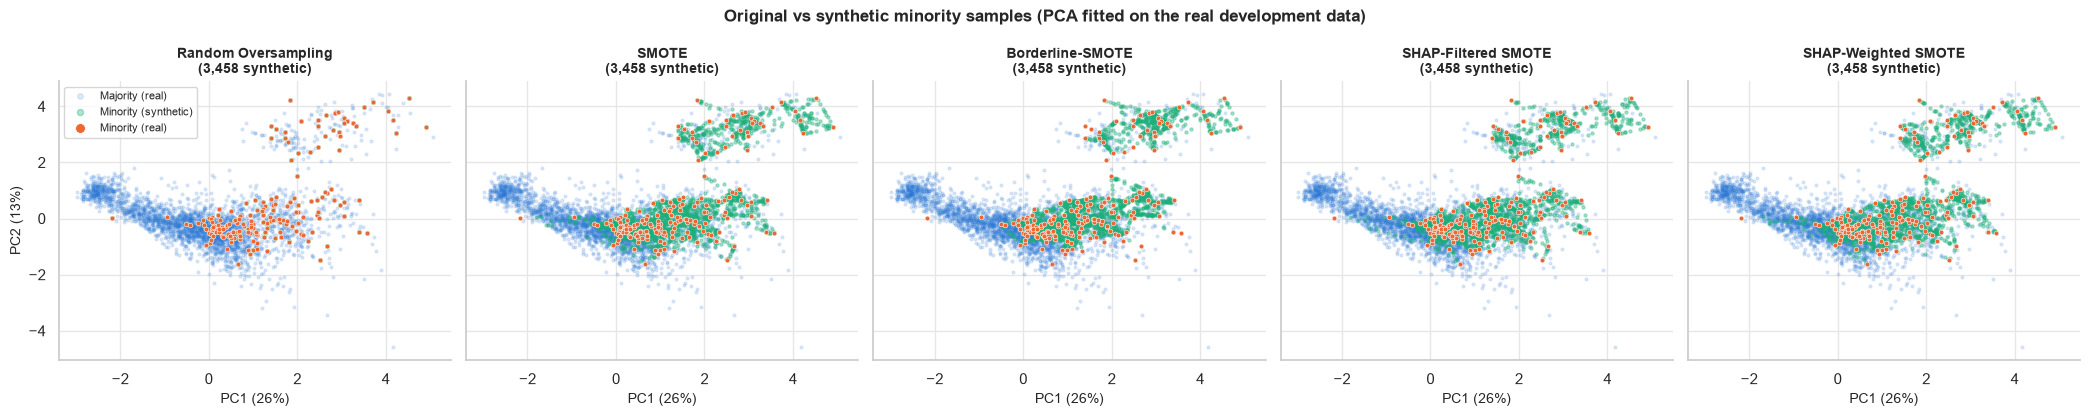

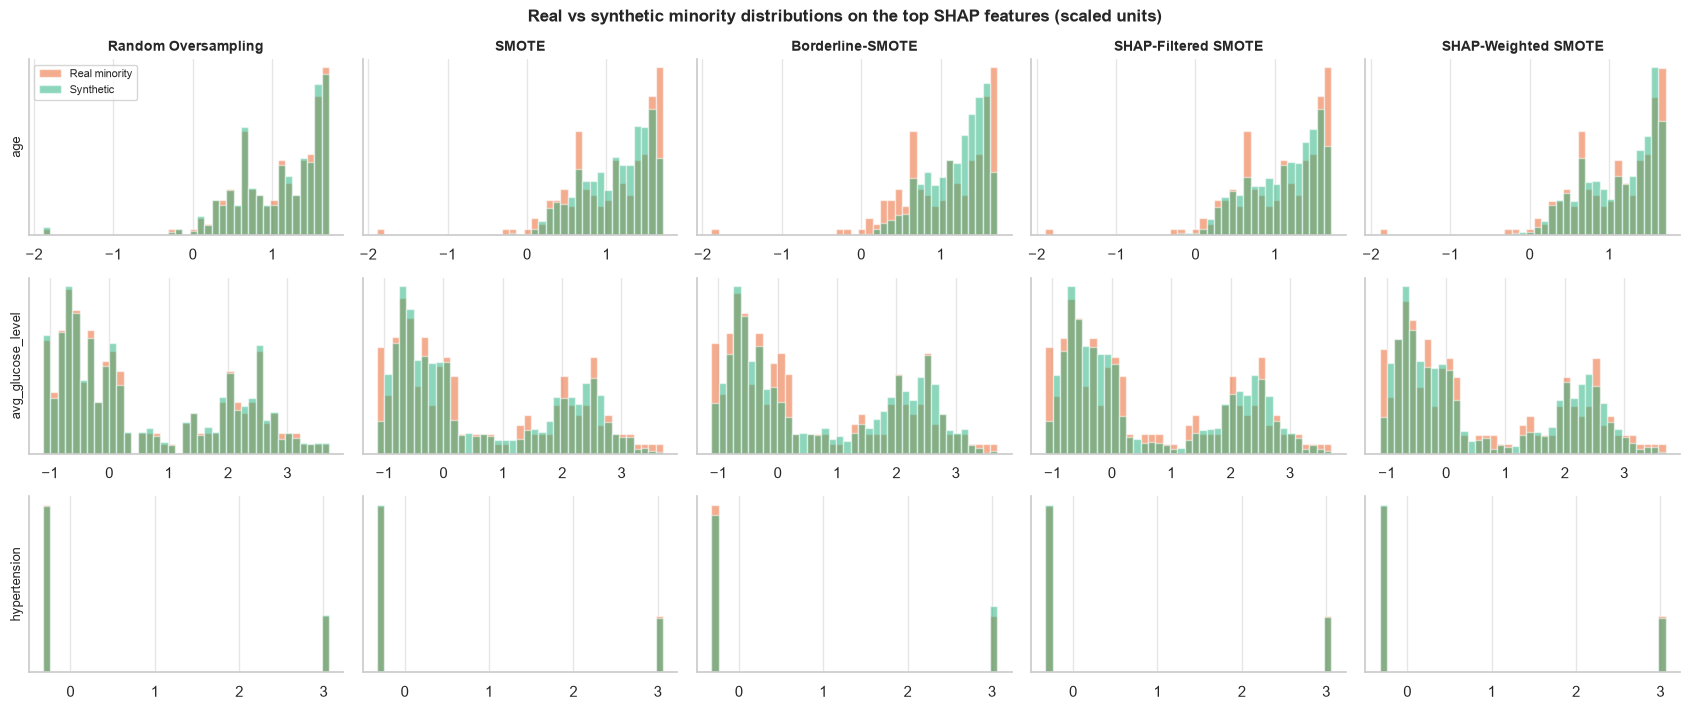

In [14]:
quality_tbl = I.synthetic_quality(final)
display(quality_tbl)
PL.pca_synthetic(final, PLOTS); plt.show()
PL.synthetic_feature_distributions(final, list(weights.index[:3]), PLOTS); plt.show()

In [15]:
files = O.save_sampling_artifacts(DIRS, final)
display(files)

,method,content,rows,file
0,Random Oversampling,synthetic samples,3458,results/stroke/synthetic_samples/random_oversa...
1,SMOTE,synthetic samples,3458,results/stroke/synthetic_samples/smote_synthet...
2,SMOTE,neighbours,935,results/stroke/neighbour_analysis/smote_neighb...
3,Borderline-SMOTE,synthetic samples,3458,results/stroke/synthetic_samples/borderline_sm...
4,Borderline-SMOTE,neighbours,935,results/stroke/neighbour_analysis/borderline_s...
5,SHAP-Filtered SMOTE,synthetic samples,3458,results/stroke/synthetic_samples/shap_filtered...
6,SHAP-Filtered SMOTE,neighbours,935,results/stroke/neighbour_analysis/shap_filtere...
7,SHAP-Weighted SMOTE,synthetic samples,3458,results/stroke/synthetic_samples/shap_weighted...
8,SHAP-Weighted SMOTE,neighbours,935,results/stroke/neighbour_analysis/shap_weighte...
9,SHAP-Filtered SMOTE,"SHAP rationale (first 2,000 rows)",2000,results/stroke/neighbour_analysis/shap_filtere...


## Stage 5: Repeated stratified cross-validation (leak-free)
For each of the 2 × 5 folds of the development set, the full chain (preprocessing → SHAP → oversampling → model) is
re-fitted on the training part with fresh objects, and scored on the untouched validation part. This gives a
mean ± standard deviation for every (method, model) pair, plus paired per-fold comparisons.

In [16]:
cv = R.run_cross_validation(dev_df, spec)
print(f"Cross-validation finished in {cv.elapsed_s / 60:.1f} min")

fold  1/10 done in   18.9 s


fold  2/10 done in   19.6 s


fold  3/10 done in   19.2 s


fold  4/10 done in   18.5 s


fold  5/10 done in   19.3 s


fold  6/10 done in   18.6 s


fold  7/10 done in   18.6 s


fold  8/10 done in   18.5 s


fold  9/10 done in   18.8 s


fold 10/10 done in   18.3 s
Cross-validation finished in 3.1 min


In [17]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: cross-validation, mean ± sd over {C.CV_SPLITS * C.CV_REPEATS} folds**"))
    display(S.cv_comparison_table(cv, model))

**Logistic Regression: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.951 ± 0.001,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.836 ± 0.019,0.189 ± 0.034,1.0 ± 0.0
Random Oversampling,0.741 ± 0.015,0.135 ± 0.009,0.791 ± 0.051,0.23 ± 0.015,0.835 ± 0.018,0.191 ± 0.037,0.739 ± 0.016
SMOTE,0.749 ± 0.014,0.133 ± 0.009,0.751 ± 0.075,0.226 ± 0.016,0.833 ± 0.022,0.19 ± 0.042,0.749 ± 0.018
Borderline-SMOTE,0.78 ± 0.017,0.142 ± 0.011,0.697 ± 0.074,0.236 ± 0.018,0.832 ± 0.02,0.189 ± 0.037,0.784 ± 0.02
SHAP-Filtered SMOTE,0.745 ± 0.017,0.131 ± 0.012,0.751 ± 0.081,0.223 ± 0.02,0.832 ± 0.021,0.192 ± 0.039,0.745 ± 0.019
SHAP-Weighted SMOTE,0.744 ± 0.015,0.131 ± 0.01,0.753 ± 0.073,0.223 ± 0.017,0.831 ± 0.022,0.191 ± 0.042,0.744 ± 0.018


**Random Forest: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.951 ± 0.001,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.832 ± 0.024,0.183 ± 0.026,1.0 ± 0.0
Random Oversampling,0.716 ± 0.028,0.121 ± 0.014,0.764 ± 0.111,0.208 ± 0.024,0.817 ± 0.026,0.165 ± 0.019,0.714 ± 0.032
SMOTE,0.766 ± 0.02,0.123 ± 0.02,0.619 ± 0.125,0.205 ± 0.034,0.801 ± 0.034,0.153 ± 0.039,0.774 ± 0.024
Borderline-SMOTE,0.809 ± 0.018,0.135 ± 0.017,0.537 ± 0.088,0.215 ± 0.026,0.809 ± 0.025,0.16 ± 0.023,0.823 ± 0.021
SHAP-Filtered SMOTE,0.897 ± 0.026,0.158 ± 0.051,0.233 ± 0.08,0.182 ± 0.041,0.797 ± 0.04,0.155 ± 0.032,0.931 ± 0.03
SHAP-Weighted SMOTE,0.883 ± 0.022,0.142 ± 0.037,0.262 ± 0.055,0.182 ± 0.039,0.793 ± 0.041,0.151 ± 0.042,0.915 ± 0.025


**XGBoost: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.948 ± 0.002,0.251 ± 0.18,0.035 ± 0.022,0.061 ± 0.039,0.826 ± 0.02,0.179 ± 0.028,0.995 ± 0.002
Random Oversampling,0.85 ± 0.014,0.157 ± 0.017,0.476 ± 0.09,0.235 ± 0.028,0.818 ± 0.018,0.171 ± 0.02,0.869 ± 0.018
SMOTE,0.905 ± 0.012,0.153 ± 0.058,0.203 ± 0.072,0.173 ± 0.061,0.805 ± 0.023,0.151 ± 0.032,0.941 ± 0.012
Borderline-SMOTE,0.904 ± 0.011,0.151 ± 0.05,0.203 ± 0.058,0.172 ± 0.05,0.811 ± 0.02,0.156 ± 0.037,0.94 ± 0.012
SHAP-Filtered SMOTE,0.935 ± 0.009,0.218 ± 0.103,0.107 ± 0.046,0.139 ± 0.053,0.815 ± 0.023,0.162 ± 0.03,0.978 ± 0.01
SHAP-Weighted SMOTE,0.94 ± 0.005,0.21 ± 0.102,0.075 ± 0.04,0.109 ± 0.055,0.814 ± 0.024,0.161 ± 0.027,0.985 ± 0.005


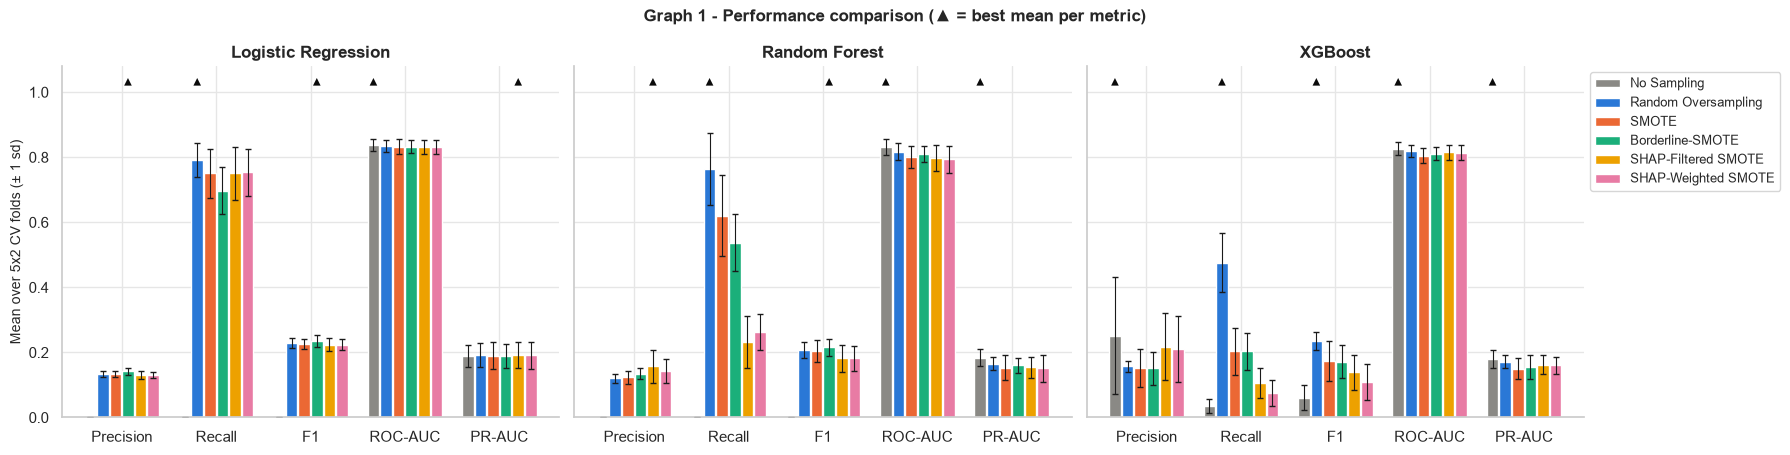

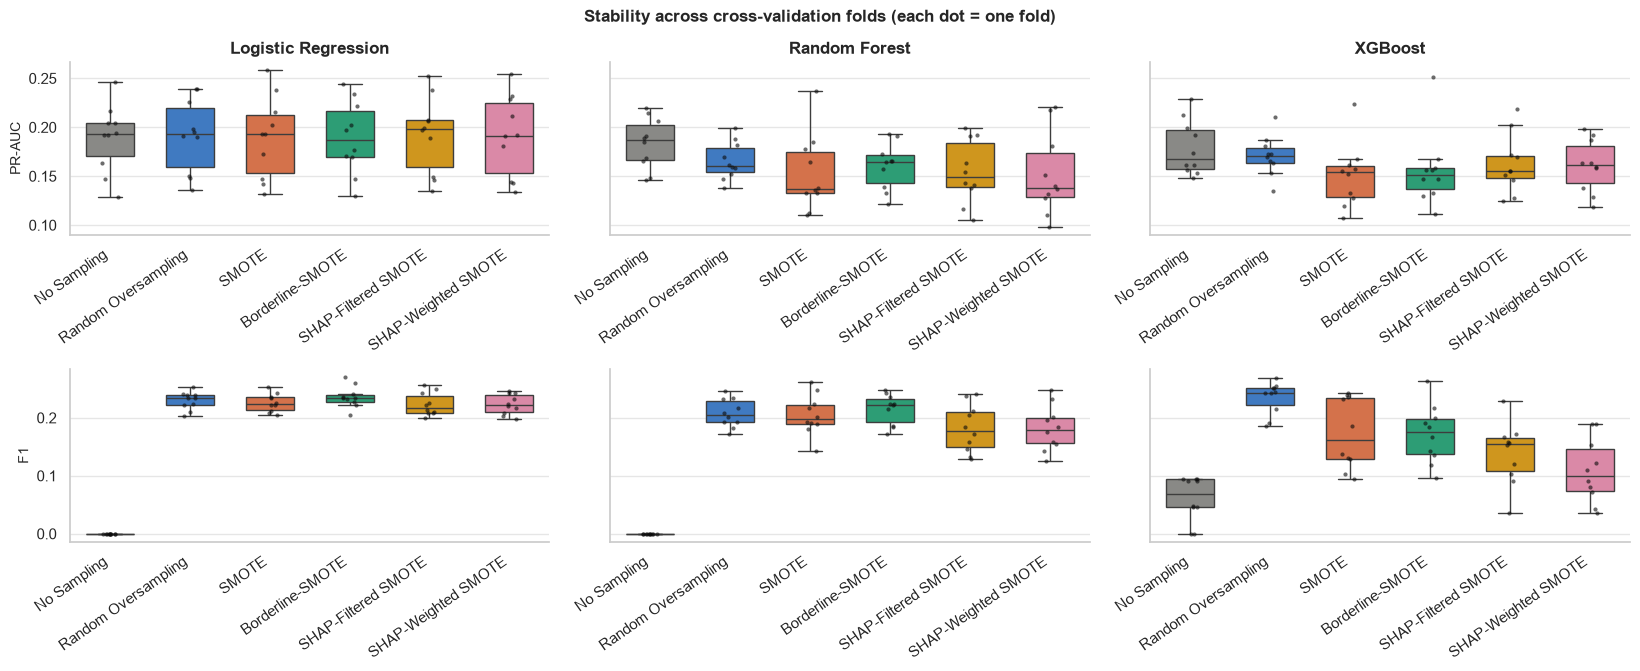

In [18]:
PL.performance_comparison(cv, PLOTS); plt.show()
PL.fold_distributions(cv, PLOTS); plt.show()

In [19]:
tests = R.paired_tests(cv)
display(Markdown("**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)"))
display(tests[tests.method.isin(C.PROPOSED_METHODS)].style.format({"mean_difference": "{:+.4f}", "p_value": "{:.3f}"})
        .apply(lambda r: ["font-weight: bold" if r.p_value < 0.05 else "" for _ in r], axis=1))

**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)

,model,method,vs,metric,mean_difference,folds_better,folds_worse,p_value
12,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,PR-AUC,+0.0025,5,5,0.846
13,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,F1,-0.0026,2,7,0.250
14,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Recall,-0.0001,2,3,1.000
15,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Precision,-0.0018,2,7,0.203
16,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,PR-AUC,+0.0015,5,5,0.922
17,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,F1,-0.0027,2,7,0.098
18,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Recall,+0.0027,2,1,0.750
19,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Precision,-0.0019,2,7,0.098
32,Random Forest,SHAP-Filtered SMOTE,SMOTE,PR-AUC,+0.0017,6,4,0.846
33,Random Forest,SHAP-Filtered SMOTE,SMOTE,F1,-0.0230,3,7,0.160


## Stage 6: Hold-out test evaluation
The models fitted in Stage 4 on the (resampled) development set are scored **once** on the untouched 25% test
set, at the 0.5 decision threshold. Test-set rankings rest on a single split and few minority cases, so read them
together with the cross-validation results in Stage 5.

In [20]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: hold-out test set**"))
    display(S.comparison_table(final, model).style.format("{:.4f}").highlight_max(axis=0, props="font-weight: bold"))
cm = final.test_metrics.set_index(["model", "method"])[["tn", "fp", "fn", "tp", "brier", "ece"]]
display(Markdown("**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**"))
display(cm)

**Logistic Regression: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9523,1.0000,0.0161,0.0317,0.8416,0.2617,1.0000
Random Oversampling,0.7316,0.1293,0.7903,0.2222,0.8436,0.2595,0.7286
SMOTE,0.7379,0.1321,0.7903,0.2263,0.8400,0.2674,0.7352
Borderline-SMOTE,0.7723,0.1477,0.7742,0.2481,0.8368,0.2575,0.7722
SHAP-Filtered SMOTE,0.7324,0.1277,0.7742,0.2192,0.8361,0.2626,0.7303
SHAP-Weighted SMOTE,0.7379,0.1340,0.8065,0.2299,0.8398,0.2619,0.7344


**Random Forest: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9515,0.0000,0.0000,0.0000,0.8441,0.2303,1.0000
Random Oversampling,0.7160,0.1170,0.7419,0.2022,0.8082,0.1821,0.7146
SMOTE,0.7324,0.1089,0.6290,0.1857,0.7984,0.1622,0.7377
Borderline-SMOTE,0.7919,0.1331,0.5968,0.2176,0.8046,0.1483,0.8018
SHAP-Filtered SMOTE,0.8897,0.1089,0.1774,0.1350,0.7839,0.1171,0.9260
SHAP-Weighted SMOTE,0.8560,0.1280,0.3387,0.1858,0.7827,0.1369,0.8824


**XGBoost: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9507,0.3333,0.0161,0.0308,0.8223,0.2427,0.9984
Random Oversampling,0.8529,0.1684,0.5161,0.2540,0.8212,0.2409,0.8701
SMOTE,0.9006,0.1963,0.3387,0.2485,0.7946,0.1572,0.9293
Borderline-SMOTE,0.8936,0.1373,0.2258,0.1707,0.7826,0.1391,0.9276
SHAP-Filtered SMOTE,0.9327,0.1667,0.0968,0.1224,0.8055,0.1650,0.9753
SHAP-Weighted SMOTE,0.9366,0.2432,0.1452,0.1818,0.8072,0.1778,0.9770


**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**

,,tn,fp,fn,tp,brier,ece
model,method,,,,,,
Logistic Regression,No Sampling,1216,0,61,1,0.0406,0.0100
Random Forest,No Sampling,1216,0,62,0,0.0416,0.0167
XGBoost,No Sampling,1214,2,61,1,0.0416,0.0113
Logistic Regression,Random Oversampling,886,330,13,49,0.1729,0.2760
Random Forest,Random Oversampling,869,347,16,46,0.1507,0.2650
XGBoost,Random Oversampling,1058,158,30,32,0.0973,0.1445
Logistic Regression,SMOTE,894,322,13,49,0.1724,0.2633
Random Forest,SMOTE,897,319,23,39,0.1364,0.2344
XGBoost,SMOTE,1130,86,41,21,0.0730,0.0945


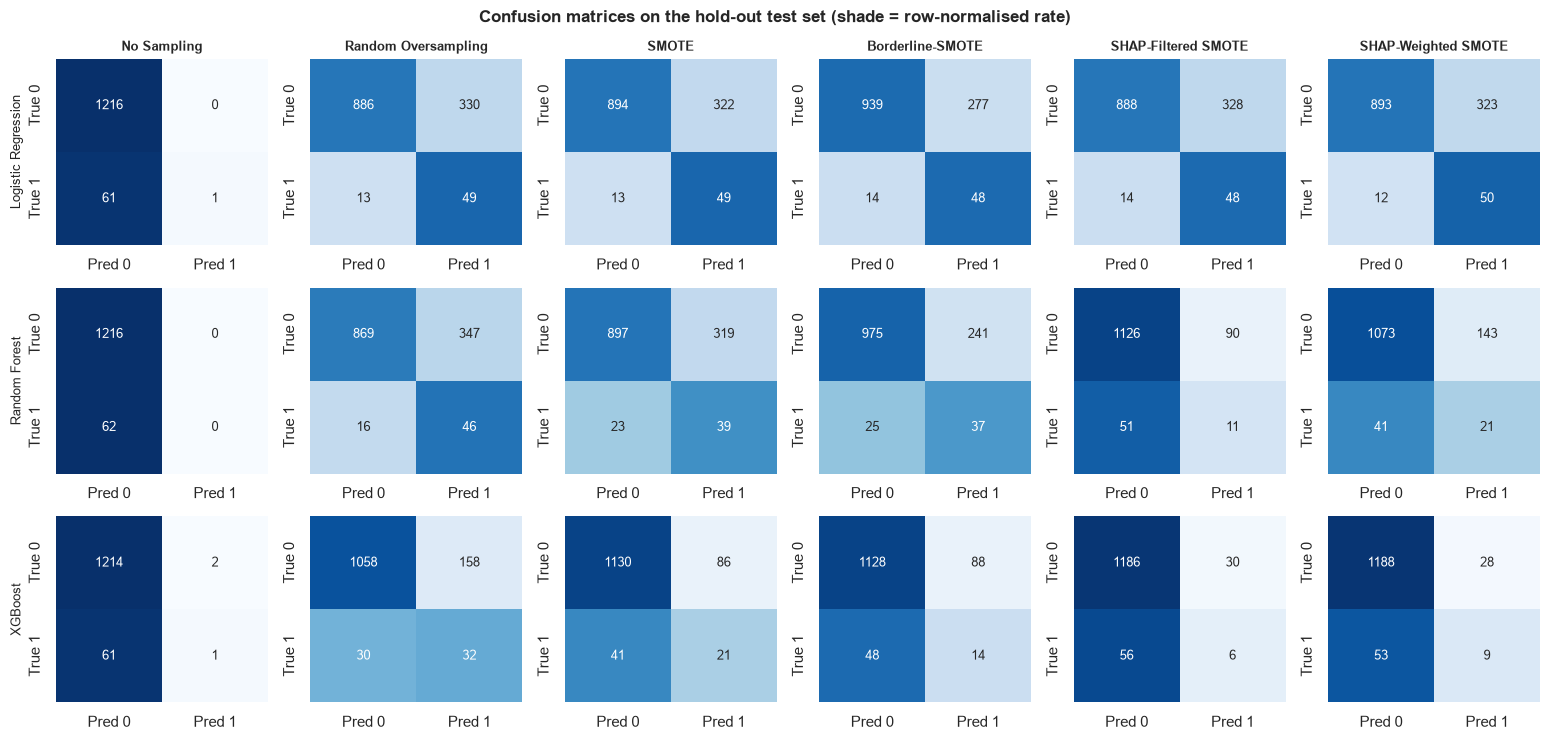

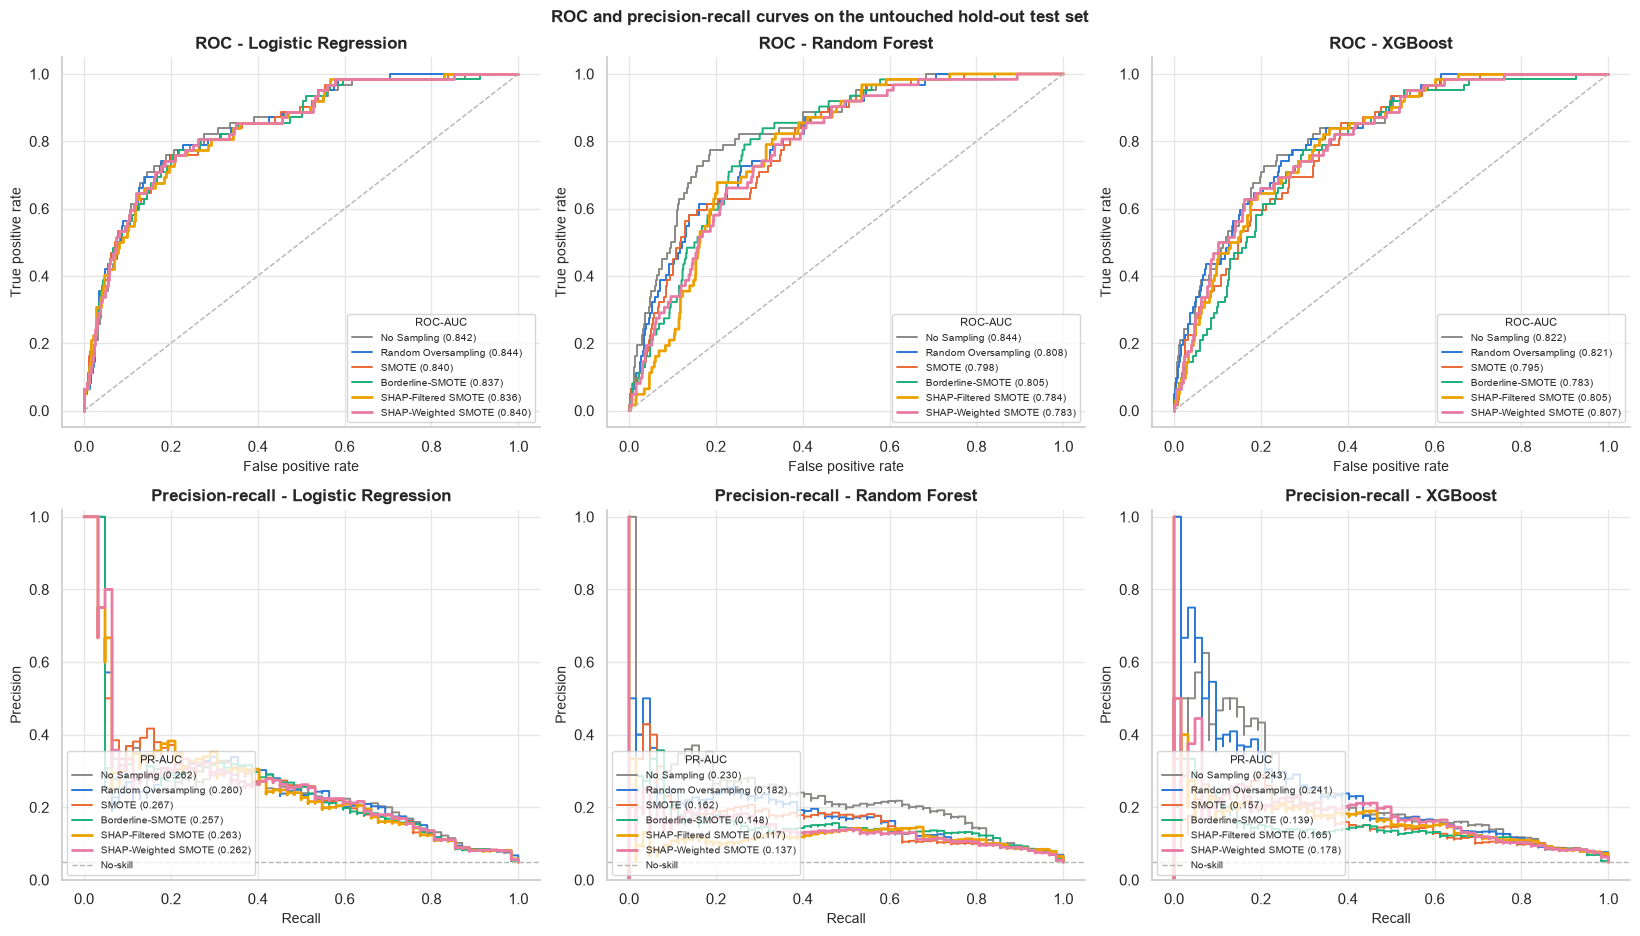

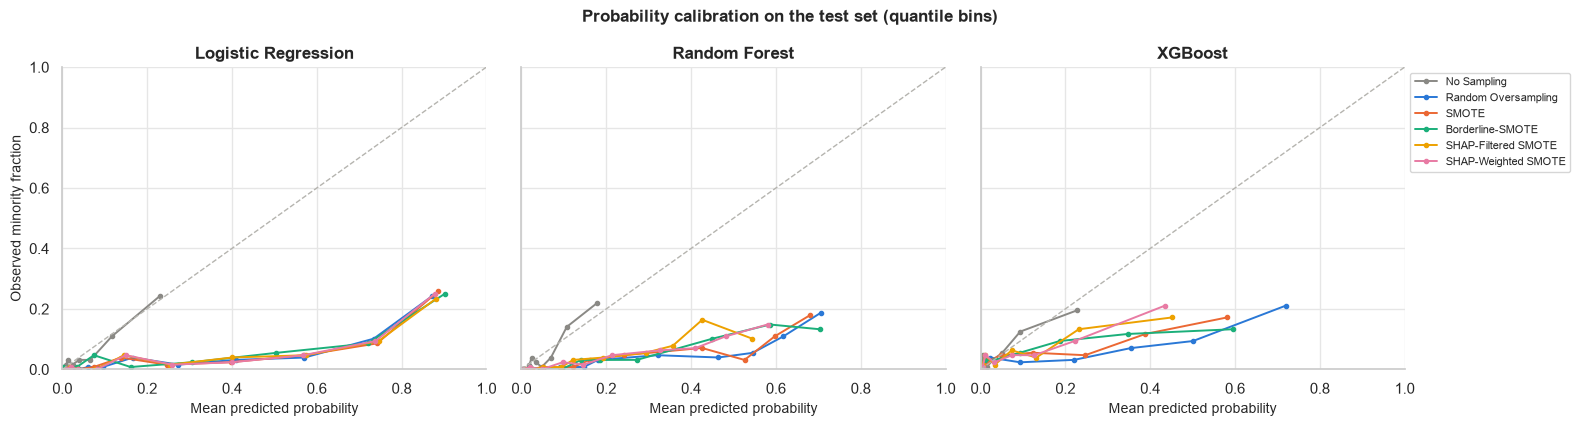

In [21]:
PL.confusion_matrices(final, PLOTS); plt.show()
PL.roc_pr_curves(final, PLOTS); plt.show()
PL.calibration_curves(final, PLOTS); plt.show()

## Stage 7: SHAP explainability comparison
Do the final models rely on different features depending on how their training data was balanced? Each final
model is explained on the same test rows (all minority rows up to 250, plus majority rows up to 500 in total).
Logistic Regression uses `LinearExplainer` with a training background; the tree models use `TreeExplainer`.
Across CV folds, the stability of each model's SHAP feature ranking is measured with Kendall τ.

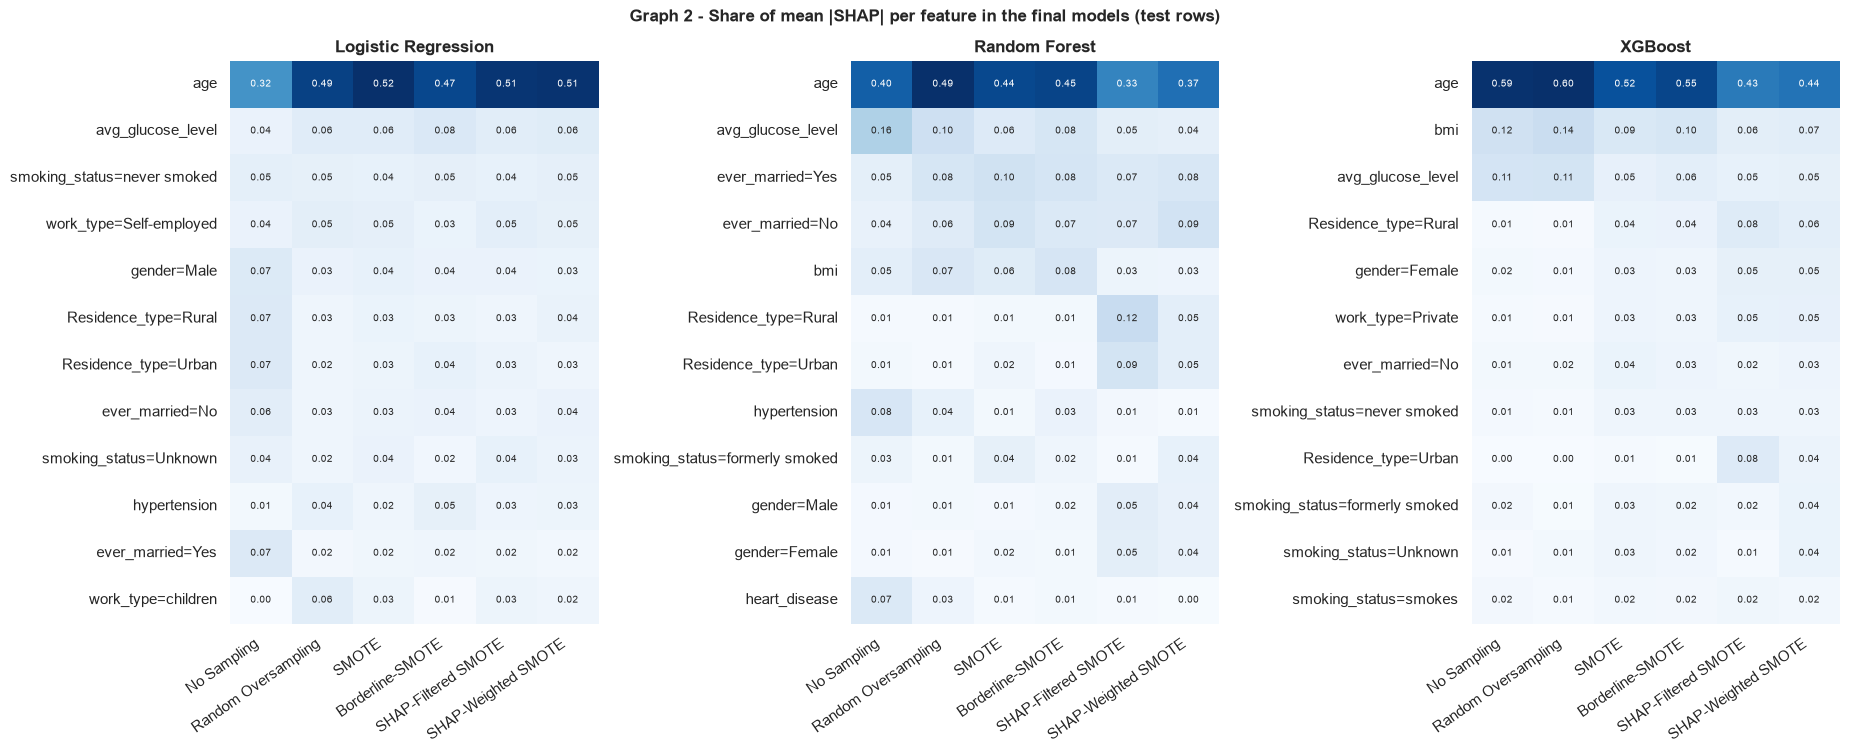

**Spearman correlation of each final model's feature-importance vector with the No Sampling model**

,Logistic Regression,Random Forest,XGBoost
No Sampling,1.0000,1.0000,1.0000
Random Oversampling,0.3519,0.8870,0.8402
SMOTE,0.5857,0.5883,0.6634
Borderline-SMOTE,0.6026,0.7974,0.7818
SHAP-Filtered SMOTE,0.5286,0.2748,0.4542
SHAP-Weighted SMOTE,0.6039,0.2922,0.5660


In [22]:
PL.shap_explainability_comparison(final, PLOTS); plt.show()
rank_corr = pd.DataFrame({model: final.importance_table(model).T.corr(method="spearman")["No Sampling"]
                          for model in C.MODEL_ORDER})
display(Markdown("**Spearman correlation of each final model's feature-importance vector with the No Sampling model**"))
display(rank_corr)

,,kendall_tau_mean,kendall_tau_std,spearman_rho_mean,spearman_rho_std,top_k_overlap
model,method,,,,,
Logistic Regression,No Sampling,0.8312,0.0466,0.9489,0.0226,0.7111
Random Forest,No Sampling,0.7697,0.0475,0.8943,0.0340,0.8688
XGBoost,No Sampling,0.6785,0.0689,0.8213,0.0602,0.6180
Logistic Regression,Random Oversampling,0.6023,0.0942,0.7545,0.0983,0.5074
Random Forest,Random Oversampling,0.7742,0.0473,0.9025,0.0337,0.8815
XGBoost,Random Oversampling,0.6993,0.0821,0.8331,0.0787,0.6381
Logistic Regression,SMOTE,0.5737,0.0772,0.7366,0.0813,0.4422
Random Forest,SMOTE,0.6970,0.0547,0.8425,0.0488,0.7577
XGBoost,SMOTE,0.8178,0.0543,0.9333,0.0286,0.6434


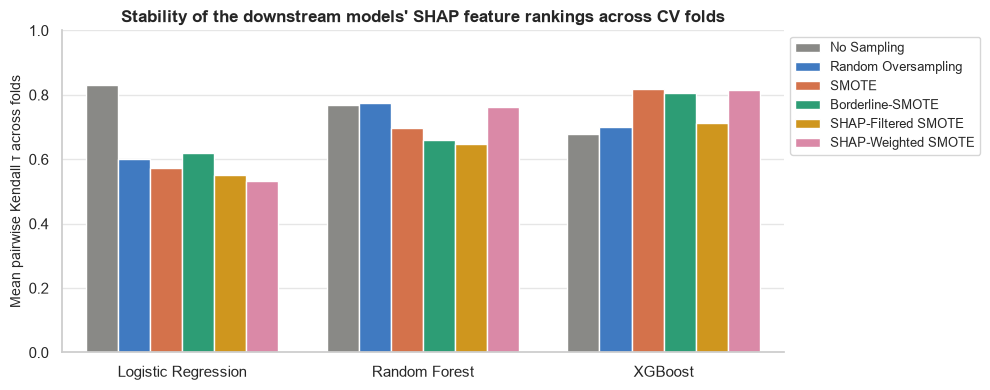

In [23]:
stability = R.attribution_stability(cv)
display(stability)
PL.attribution_stability_plot(stability, PLOTS); plt.show()

## Stage 8: Saved outputs and summary
Every table and figure is saved under `results/<dataset>/` (same layout for all datasets):
`metrics/`, `synthetic_samples/`, `neighbour_analysis/` and `plots/`.

In [24]:
saved = O.save_metrics(DIRS, dev_df, test_df, cv, final, stability, tests, quality_tbl)
display(saved)
print("plots:", ", ".join(sorted(p.name for p in PLOTS.glob("*.png"))))

,file
0,results/stroke/metrics/split_assignment.csv
1,results/stroke/metrics/cv_fold_metrics.csv
2,results/stroke/metrics/cv_mean_metrics.csv
3,results/stroke/metrics/cv_summary_mean_sd.csv
4,results/stroke/metrics/cv_sampling_runtime.csv
5,results/stroke/metrics/test_metrics.csv
6,results/stroke/metrics/final_sampling_counts.csv
7,results/stroke/metrics/attribution_stability.csv
8,results/stroke/metrics/paired_tests_vs_smote.csv
9,results/stroke/metrics/synthetic_quality.csv


plots: 01_class_distribution.png, 02_feature_distributions.png, 03_correlation_heatmap.png, 04_class_comparison.png, 05_balanced_class_counts.png, 06_shap_feature_weights.png, 07_shap_summary_preliminary_model.png, 08_pca_original_vs_synthetic.png, 09_synthetic_feature_distributions.png, 10_graph1_performance_comparison.png, 11_cv_fold_stability.png, 12_roc_pr_curves.png, 13_confusion_matrices.png, 14_calibration_curves.png, 15_graph2_shap_explainability_comparison.png, 16_attribution_stability.png


### Final summary
Numbers below are computed from this run, not typed by hand.

In [25]:
display(Markdown(f"**Dataset:** {spec.title}, {len(df):,} rows, {len(spec.features)} raw features "
                 f"({len(pre.feature_names_)} model columns after encoding)."))
display(D.overview(df, spec))
display(Markdown("**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, "
                 "one-hot encoding and standard scaling fitted on training rows only; oversampling only inside "
                 "training folds."))
display(Markdown("**Oversampling results (final development-set fit):**"))
display(final.sampling.join(quality_tbl.reindex(columns=["majority_share_in_5nn", "mean_wasserstein_distance",
                                          "correlation_matrix_similarity", "detectability_auc_all", "detectability_auc_numeric"]), how="left"))
display(Markdown("**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**"))
display(S.dataset_findings(cv, tests, quality_tbl).T)
display(Markdown("**Findings derived from the numbers:**\n" + "\n".join(f"- {l}" for l in S.findings_text(cv, tests, quality_tbl))))

**Dataset:** Stroke Prediction, 5,110 rows, 10 raw features (21 model columns after encoding).

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Stroke Prediction,Clinical risk prediction,5110,5,5,4861,249,4.87%,19.5 : 1,1 : 19.5


**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, one-hot encoding and standard scaling fitted on training rows only; oversampling only inside training folds.

**Oversampling results (final development-set fit):**

,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds,majority_share_in_5nn,mean_wasserstein_distance,correlation_matrix_similarity,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,
No Sampling,3645,187,0,3645,187,0.0061,NaN,NaN,NaN,NaN,NaN
Random Oversampling,3645,187,3458,3645,3645,1.3882,0.7193,0.0074,0.9958,NaN,NaN
SMOTE,3645,187,3458,3645,3645,0.1861,0.6787,0.0403,0.9846,0.8082,0.6328
Borderline-SMOTE,3645,187,3458,3645,3645,0.1917,0.6313,0.0649,0.9064,0.7720,0.6165
SHAP-Filtered SMOTE,3645,187,3458,3645,3645,2.4048,0.6912,0.0579,0.9883,0.9251,0.5868
SHAP-Weighted SMOTE,3645,187,3458,3645,3645,2.4121,0.6903,0.0588,0.9839,0.9621,0.5986


**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**

model,Logistic Regression,Random Forest,XGBoost
best PR-AUC,SHAP-Filtered SMOTE (0.192),No Sampling (0.183),No Sampling (0.179)
best F1,Borderline-SMOTE (0.236),Borderline-SMOTE (0.215),Random Oversampling (0.235)
best recall,Random Oversampling (0.791),Random Oversampling (0.764),Random Oversampling (0.476)
SHAP-F - SMOTE PR-AUC,+0.002 (p=0.85),+0.002 (p=0.85),+0.012 (p=0.70)
SHAP-F - SMOTE F1,-0.003 (p=0.25),-0.023 (p=0.16),-0.034 (p=0.13)
SHAP-F - SMOTE Recall,-0.000 (p=1.00),-0.387 (p=0.00),-0.096 (p=0.00)
SHAP-F - SMOTE Precision,-0.002 (p=0.20),+0.035 (p=0.04),+0.065 (p=0.19)
SHAP-W - SMOTE PR-AUC,+0.001 (p=0.92),-0.001 (p=1.00),+0.010 (p=0.23)
SHAP-W - SMOTE F1,-0.003 (p=0.10),-0.023 (p=0.06),-0.065 (p=0.04)
SHAP-W - SMOTE Recall,+0.003 (p=0.75),-0.357 (p=0.00),-0.128 (p=0.00)


**Findings derived from the numbers:**
- Logistic Regression: PR-AUC ranking = SHAP-Filtered SMOTE 0.192 > Random Oversampling 0.191 > SHAP-Weighted SMOTE 0.191 > SMOTE 0.190 > Borderline-SMOTE 0.189 > No Sampling 0.189
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.002 (5/10 folds better, p=0.846, not significant); F1 -0.003 (2/9 folds better, p=0.250, not significant); Recall -0.000 (2/5 folds better, p=1.000, not significant); Precision -0.002 (2/9 folds better, p=0.203, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.001 (5/10 folds better, p=0.922, not significant); F1 -0.003 (2/9 folds better, p=0.098, not significant); Recall +0.003 (2/3 folds better, p=0.750, not significant); Precision -0.002 (2/9 folds better, p=0.098, not significant)
- Random Forest: PR-AUC ranking = No Sampling 0.183 > Random Oversampling 0.165 > Borderline-SMOTE 0.160 > SHAP-Filtered SMOTE 0.155 > SMOTE 0.153 > SHAP-Weighted SMOTE 0.151
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.002 (6/10 folds better, p=0.846, not significant); F1 -0.023 (3/10 folds better, p=0.160, not significant); Recall -0.387 (0/10 folds better, p=0.002, significant); Precision +0.035 (7/10 folds better, p=0.037, significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC -0.001 (6/10 folds better, p=1.000, not significant); F1 -0.023 (1/10 folds better, p=0.064, not significant); Recall -0.357 (0/10 folds better, p=0.002, significant); Precision +0.019 (7/10 folds better, p=0.037, significant)
- XGBoost: PR-AUC ranking = No Sampling 0.179 > Random Oversampling 0.171 > SHAP-Filtered SMOTE 0.162 > SHAP-Weighted SMOTE 0.161 > Borderline-SMOTE 0.156 > SMOTE 0.151
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.012 (5/10 folds better, p=0.695, not significant); F1 -0.034 (3/10 folds better, p=0.131, not significant); Recall -0.096 (0/10 folds better, p=0.002, significant); Precision +0.065 (6/10 folds better, p=0.193, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.010 (7/10 folds better, p=0.232, not significant); F1 -0.065 (2/10 folds better, p=0.037, significant); Recall -0.128 (0/10 folds better, p=0.002, significant); Precision +0.057 (7/10 folds better, p=0.131, not significant)
- Synthetic rows' majority share among 5 nearest real rows (lower = less overlap): Real minority (reference) 0.897, Random Oversampling 0.719, SMOTE 0.679, Borderline-SMOTE 0.631, SHAP-Filtered SMOTE 0.691, SHAP-Weighted SMOTE 0.690
- Mean marginal Wasserstein distance synthetic vs real minority (lower = closer): Random Oversampling 0.007, SMOTE 0.040, Borderline-SMOTE 0.065, SHAP-Filtered SMOTE 0.058, SHAP-Weighted SMOTE 0.059
- Correlation-structure similarity synthetic vs real minority (1 = identical): Random Oversampling 0.996, SMOTE 0.985, Borderline-SMOTE 0.906, SHAP-Filtered SMOTE 0.988, SHAP-Weighted SMOTE 0.984
- Real-vs-synthetic detectability AUC, all columns / numeric only (0.5 = indistinguishable): SMOTE 0.808 / 0.633, Borderline-SMOTE 0.772 / 0.616, SHAP-Filtered SMOTE 0.925 / 0.587, SHAP-Weighted SMOTE 0.962 / 0.599

### Interpretation: Stroke Prediction (19.5 : 1)

**Which method performed best?** This is a hard problem for every method: CV PR-AUC is only 0.15–0.19 (the
no-skill level is 0.049) and ROC-AUC is 0.79–0.84. Ranked by threshold-free PR-AUC, the methods are almost tied
and Logistic Regression is the best model for all of them (0.189–0.192). At the 0.5 threshold, oversampling is
essential: without it the models predict almost no strokes (recall 0.00–0.04). Random Oversampling gives the best
CV F1 with Random Forest (0.208) and XGBoost (0.235), and Borderline-SMOTE the best with Logistic Regression (0.236).

**Did SHAP-guided SMOTE improve minority-class detection?** No, and for the tree models it clearly made it
worse. With Logistic Regression both SHAP methods match SMOTE (recall 0.75). With Random Forest, recall drops from
0.62 (SMOTE) to 0.23 (SHAP-Filtered) and 0.26 (SHAP-Weighted); with XGBoost, from 0.20 to 0.11 and 0.08. Each of
these four drops occurs in all 10 folds (Wilcoxon p = 0.002).

**PR-AUC and F1?** PR-AUC is unchanged: every difference from SMOTE is between −0.001 and +0.012, none
significant. F1 is lower for the tree models (−0.02 to −0.07). The −0.065 for SHAP-Weighted SMOTE with XGBoost is
significant (p = 0.037).

**Precision?** It improves where recall collapses: +0.035 (SHAP-Filtered, RF, p = 0.037), +0.019
(SHAP-Weighted, RF, p = 0.037), about +0.06 with XGBoost (not significant). The tree models trained on SHAP-guided
data become more conservative rather than better at ranking: PR-AUC, which does not depend on the threshold,
does not move.

**Did the synthetic samples preserve feature relationships?** On the numeric features, slightly better than
SMOTE. A Random Forest separates SHAP-guided synthetic rows from real stroke patients on the numeric features
with AUC 0.59–0.60, versus 0.63 for SMOTE (0.5 = indistinguishable). Correlation structure is preserved
(similarity 0.98–0.99), and paired parents have more similar explanations (SHAP cosine 0.81–0.88 vs 0.74).
**The categorical features are the failure point.** SHAP gives the one-hot columns (work type, residence,
smoking status) low weight, so it pairs patients from different categories. Interpolation then leaves 3.7–3.9
one-hot columns per synthetic row between 0 and 1, versus 2.3 for SMOTE. On all columns, the SHAP-guided rows
are detectable with AUC 0.93 (Filtered) and 0.96 (Weighted), versus 0.81 for SMOTE. The tree models can learn
"fractional category value → stroke", a pattern that never occurs in real test patients. This explains why their
recall collapses, while Logistic Regression, which can hardly exploit such artefacts, is unaffected.

**Where did SHAP-guided SMOTE fail?** On mixed-type data. Because SHAP down-weights low-importance categorical
columns, interpolation produces unrealistic category values more often than plain SMOTE does, and tree models
over-fit to them. Two fixes are implied but outside the compared methods: snap one-hot groups back to a valid
category, or use a categorical-aware variant (SMOTE-NC-style). This is the clearest negative result of the benchmark.